## Run Lusaka, Zambia example

In [25]:
import covasim as cv    #once covasim is installed. You also need to make sure the kernel you work with in jupyter notebook has covasim installed 
import matplotlib.pyplot as plt
import numpy as np


## 1. Start simulation

In [26]:
sim = cv.Sim(
    pop_size=20_000,
    pop_type='rank',
    density_raster='data/lusaka_city_raster.tif',
    pop_infected=20,
    n_days=100,
    n_imports=0,
    boundary_shapefile='data/lusaka_city_adm4.geojson',
    sewershed_file='data/lusaka_city_sewershed.geojson',
)
sim.run()


/storage/hcraddock/GitHub/covasim4wastewater/covasim/population.py:67: RuntimeWarning: 
The boundary file has no "population" column, so regions are weighted by their area. Add a "population" column to weight by population (it is not needed when pop_type="rank" uses a density_raster).
  cvm.warn(


Initializing sim with 20000 people for 100 days
  Running 2020-03-01 ( 0/100) (32.03 s)  ———————————————————— 1%
  Running 2020-03-11 (10/100) (32.16 s)  ••—————————————————— 11%
  Running 2020-03-21 (20/100) (32.27 s)  ••••———————————————— 21%
  Running 2020-03-31 (30/100) (32.39 s)  ••••••—————————————— 31%
  Running 2020-04-10 (40/100) (32.54 s)  ••••••••———————————— 41%
  Running 2020-04-20 (50/100) (32.68 s)  ••••••••••—————————— 50%
  Running 2020-04-30 (60/100) (32.89 s)  ••••••••••••———————— 60%
  Running 2020-05-10 (70/100) (33.13 s)  ••••••••••••••—————— 70%
  Running 2020-05-20 (80/100) (33.42 s)  ••••••••••••••••———— 80%
  Running 2020-05-30 (90/100) (33.69 s)  ••••••••••••••••••—— 90%
  Running 2020-06-09 (100/100) (34.23 s)  •••••••••••••••••••• 100%

Simulation summary:
       18,668 cumulative infections
        2,648 cumulative reinfections
       18,166 cumulative infectious
       11,766 cumulative symptomatic cases
          879 cumulative severe cases
          287

Sim(<no label>; 2020-03-01 to 2020-06-09; pop: 20000 rank; epi: 18668⚙, 96☠)

## 2. Add reporting 'Interventions'

In [27]:
sim = cv.Sim(
    pop_size=20_000,
    pop_type='rank',
    density_raster='data/lusaka_city_raster.tif',
    pop_infected=20,
    n_days=100,
    n_imports=0,
    boundary_shapefile='data/lusaka_city_adm4.geojson',
    sewershed_file='data/lusaka_city_sewershed.geojson',
    interventions=cv.test_prob(symp_prob=0.1)               #Add testing so that we recover reported cases. Reporting = 10% of symptomatic cases
)
sim.run()


/storage/hcraddock/GitHub/covasim4wastewater/covasim/population.py:67: RuntimeWarning: 
The boundary file has no "population" column, so regions are weighted by their area. Add a "population" column to weight by population (it is not needed when pop_type="rank" uses a density_raster).
  cvm.warn(


Initializing sim with 20000 people for 100 days
  Running 2020-03-01 ( 0/100) (29.75 s)  ———————————————————— 1%
  Running 2020-03-11 (10/100) (29.99 s)  ••—————————————————— 11%
  Running 2020-03-21 (20/100) (30.21 s)  ••••———————————————— 21%
  Running 2020-03-31 (30/100) (30.42 s)  ••••••—————————————— 31%
  Running 2020-04-10 (40/100) (30.61 s)  ••••••••———————————— 41%
  Running 2020-04-20 (50/100) (30.83 s)  ••••••••••—————————— 50%
  Running 2020-04-30 (60/100) (31.06 s)  ••••••••••••———————— 60%
  Running 2020-05-10 (70/100) (31.35 s)  ••••••••••••••—————— 70%
  Running 2020-05-20 (80/100) (31.66 s)  ••••••••••••••••———— 80%
  Running 2020-05-30 (90/100) (32.02 s)  ••••••••••••••••••—— 90%
  Running 2020-06-09 (100/100) (32.37 s)  •••••••••••••••••••• 100%

Simulation summary:
       14,745 cumulative infections
        1,448 cumulative reinfections
       14,069 cumulative infectious
        9,220 cumulative symptomatic cases
          746 cumulative severe cases
          222

Sim(<no label>; 2020-03-01 to 2020-06-09; pop: 20000 rank; epi: 14745⚙, 61☠)

## 3. Plot True Infections vs Reported Cases

In [ ]:
#True infections
true_infections = np.array(sim.results['new_infections'].values)

#Reported Cases
reported = np.array(sim.results['new_diagnoses'].values)

#Number of days
num_days = np.arange(len(true_infections))

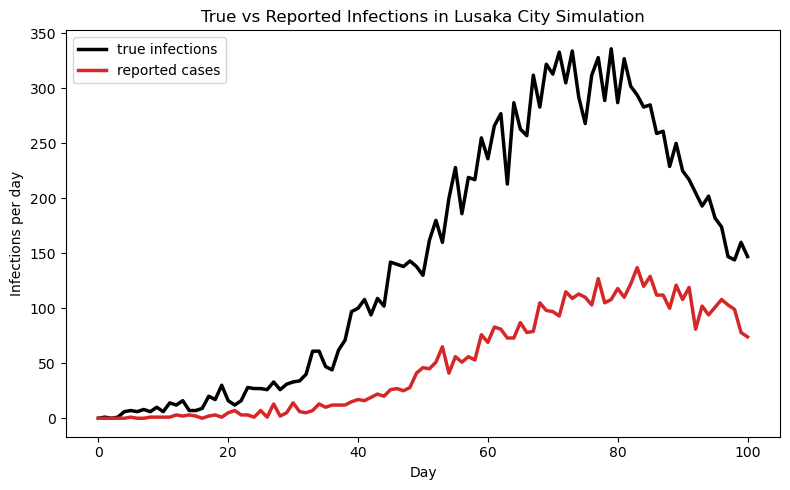

In [7]:
#Set up figure and axes
fig, ax = plt.subplots(figsize=(8, 5))

#Plot days vs true infections
ax.plot(num_days, true_infections, color='black', lw=2.5, label='true infections')

#Plot days vs Reported cases
ax.plot(num_days, reported, color='tab:red', lw=2.5, label='reported cases')

#Set axis labels and legend
ax.set_xlabel('Day')
ax.set_ylabel('Infections per day')
ax.set_title('True vs Reported Infections in Lusaka City Simulation')
ax.legend()
plt.tight_layout()
plt.show()
#plt.savefig('true_vs_reported.png', dpi=150) #If we wanted to save the figure 


## Part 2: Varying parameters such as the transmission rate - beta

In [14]:
#Double beta 
beta_new = 0.016*2
beta_new

0.032

In [30]:
# ---------------------------------------------------------------------------
# Cell 1: sim2 = the same sim with a different beta (the only change)
# ---------------------------------------------------------------------------
sim2 = cv.Sim(
    pop_size=20_000,
    pop_type='rank',
    density_raster='data/lusaka_city_raster.tif',
    pop_infected=20,
    n_days=100,
    n_imports=0,
    boundary_shapefile='data/lusaka_city_adm4.geojson',
    sewershed_file='data/lusaka_city_sewershed.geojson',
    interventions=cv.test_prob(symp_prob=0.1),    # each symptomatic person has a 10% chance of being tested each day
    beta=beta_new,                                # the only change: the Covasim default is 0.016
    rand_seed=1,                                  # the same seed as sim, so the population and the random draws start the same
)
sim2.run()

/storage/hcraddock/GitHub/covasim4wastewater/covasim/population.py:67: RuntimeWarning: 
The boundary file has no "population" column, so regions are weighted by their area. Add a "population" column to weight by population (it is not needed when pop_type="rank" uses a density_raster).
  cvm.warn(


Initializing sim with 20000 people for 100 days
  Running 2020-03-01 ( 0/100) (22.42 s)  ———————————————————— 1%
  Running 2020-03-11 (10/100) (22.66 s)  ••—————————————————— 11%
  Running 2020-03-21 (20/100) (22.89 s)  ••••———————————————— 21%
  Running 2020-03-31 (30/100) (23.24 s)  ••••••—————————————— 31%
  Running 2020-04-10 (40/100) (23.42 s)  ••••••••———————————— 41%
  Running 2020-04-20 (50/100) (23.68 s)  ••••••••••—————————— 50%
  Running 2020-04-30 (60/100) (23.95 s)  ••••••••••••———————— 60%
  Running 2020-05-10 (70/100) (24.28 s)  ••••••••••••••—————— 70%
  Running 2020-05-20 (80/100) (24.53 s)  ••••••••••••••••———— 80%
  Running 2020-05-30 (90/100) (24.86 s)  ••••••••••••••••••—— 90%
  Running 2020-06-09 (100/100) (25.19 s)  •••••••••••••••••••• 100%

Simulation summary:
       23,914 cumulative infections
        5,068 cumulative reinfections
       23,870 cumulative infectious
       15,004 cumulative symptomatic cases
        1,126 cumulative severe cases
          347

Sim(<no label>; 2020-03-01 to 2020-06-09; pop: 20000 rank; epi: 23914⚙, 117☠)

sim: beta = 0.016: 14,725 true infections, 5,109 reported (35%); infections peak on day 79
sim2: beta = 0.032: 23,894 true infections, 8,846 reported (37%); infections peak on day 40


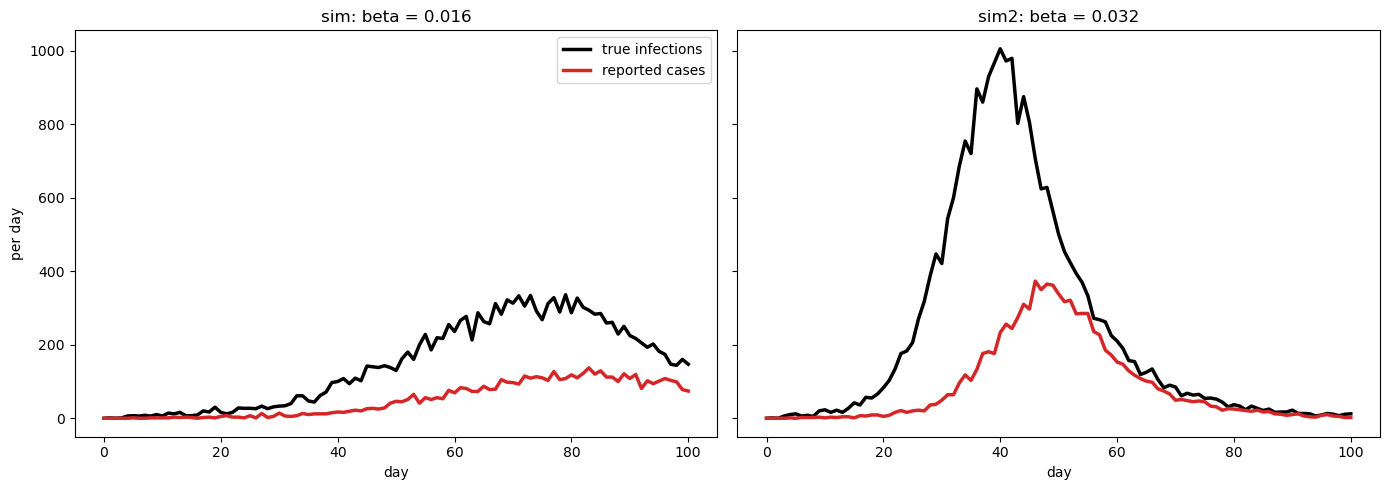

In [31]:
# ---------------------------------------------------------------------------
# Cell 2: true infections and reported cases for each sim, side by side
# ---------------------------------------------------------------------------
sims = [('sim', sim), ('sim2', sim2)]
fig, ax = plt.subplots(1, len(sims), figsize=(7*len(sims), 5), sharey=True)    # the same y axis, so the two sims can be compared directly
for a, (name, s) in zip(ax, sims):
    true_inf = np.array(s.results['new_infections'].values)
    reported = np.array(s.results['new_diagnoses'].values)
    days = np.arange(len(true_inf))
    a.plot(days, true_inf, color='black', lw=2.5, label='true infections')
    a.plot(days, reported, color='tab:red', lw=2.5, label='reported cases')
    a.set_title(f"{name}: beta = {s['beta']:g}")
    a.set_xlabel('day')
    share = f'{reported.sum()/true_inf.sum():.0%}' if true_inf.sum() > 0 else 'n/a'
    print(f"{name}: beta = {s['beta']:g}: {true_inf.sum():,.0f} true infections, {reported.sum():,.0f} reported ({share}); infections peak on day {true_inf.argmax()}")
ax[0].set_ylabel('per day')
ax[0].legend()
plt.tight_layout()
plt.savefig('beta_comparison.png', dpi=150)
plt.show()


## Part 3: Change Reporting frequency (testing rate) - increase it
- We increase the reporting frequency of symptomatic infections (sympotmatic probability; symp_prob) from 0.1 (10%) to 0.5 (50%) and see the effect that has on the epidemic

In [32]:
# ---------------------------------------------------------------------------
# Cell 1: sim2 = the same sim with a different beta (the only change)
# ---------------------------------------------------------------------------
sim3 = cv.Sim(
    pop_size=20_000,
    pop_type='rank',
    density_raster='data/lusaka_city_raster.tif',
    pop_infected=20,
    n_days=100,
    n_imports=0,
    boundary_shapefile='data/lusaka_city_adm4.geojson',
    sewershed_file='data/lusaka_city_sewershed.geojson',
    interventions=cv.test_prob(symp_prob=0.5),    # each symptomatic person has a 10% chance of being tested each day
    rand_seed=1,                                  # the same seed as sim, so the population and the random draws start the same
)
sim3.run()

/storage/hcraddock/GitHub/covasim4wastewater/covasim/population.py:67: RuntimeWarning: 
The boundary file has no "population" column, so regions are weighted by their area. Add a "population" column to weight by population (it is not needed when pop_type="rank" uses a density_raster).
  cvm.warn(


Initializing sim with 20000 people for 100 days
  Running 2020-03-01 ( 0/100) (20.88 s)  ———————————————————— 1%
  Running 2020-03-11 (10/100) (20.96 s)  ••—————————————————— 11%
  Running 2020-03-21 (20/100) (21.02 s)  ••••———————————————— 21%
  Running 2020-03-31 (30/100) (21.10 s)  ••••••—————————————— 31%
  Running 2020-04-10 (40/100) (21.21 s)  ••••••••———————————— 41%
  Running 2020-04-20 (50/100) (21.34 s)  ••••••••••—————————— 50%
  Running 2020-04-30 (60/100) (21.47 s)  ••••••••••••———————— 60%
  Running 2020-05-10 (70/100) (21.60 s)  ••••••••••••••—————— 70%
  Running 2020-05-20 (80/100) (21.87 s)  ••••••••••••••••———— 80%
  Running 2020-05-30 (90/100) (22.05 s)  ••••••••••••••••••—— 90%
  Running 2020-06-09 (100/100) (22.21 s)  •••••••••••••••••••• 100%

Simulation summary:
        4,511 cumulative infections
          136 cumulative reinfections
        4,078 cumulative infectious
        2,714 cumulative symptomatic cases
          233 cumulative severe cases
           83

Sim(<no label>; 2020-03-01 to 2020-06-09; pop: 20000 rank; epi: 4511⚙, 28☠)

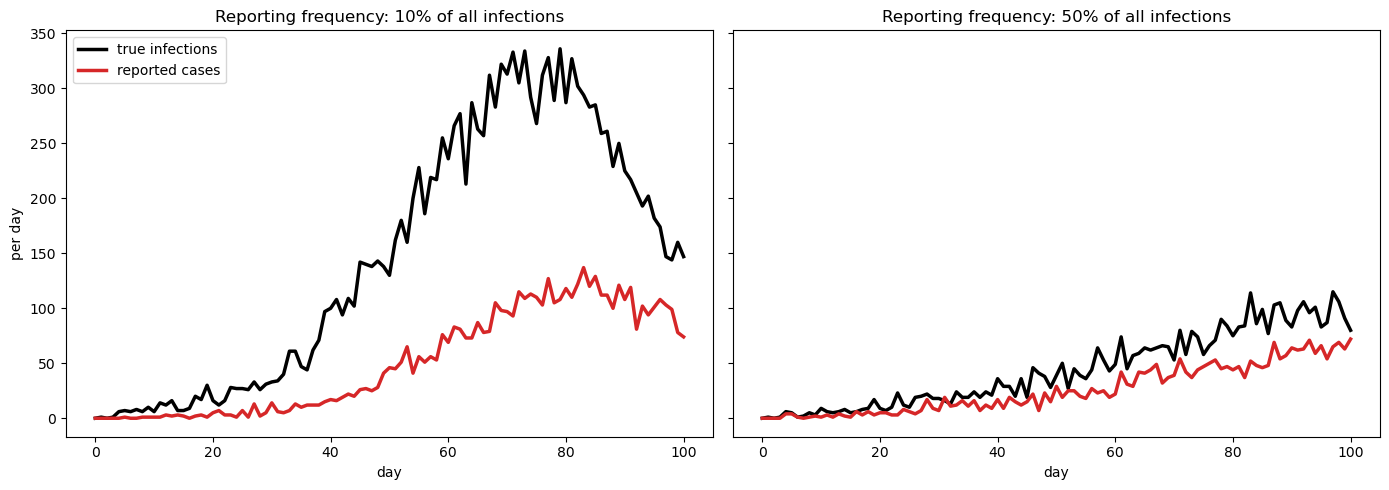

In [35]:
# ---------------------------------------------------------------------------
# Cell 2: true infections and reported cases for each sim, side by side
# ---------------------------------------------------------------------------
sims = [('sim',  sim,  'Reporting frequency: 10% of all infections'),
        ('sim3', sim3, 'Reporting frequency: 50% of all infections')]
fig, ax = plt.subplots(1, len(sims), figsize=(7*len(sims), 5), sharey=True)    # the same y axis, so the two sims can be compared directly
for a, (name, s, title) in zip(ax, sims):
    true_inf = np.array(s.results['new_infections'].values)
    reported = np.array(s.results['new_diagnoses'].values)
    days = np.arange(len(true_inf))
    a.plot(days, true_inf, color='black', lw=2.5, label='true infections')
    a.plot(days, reported, color='tab:red', lw=2.5, label='reported cases')
    a.set_xlabel('day')
    a.set_title(title)
    share = f'{reported.sum()/true_inf.sum():.0%}' if true_inf.sum() > 0 else 'n/a'
    #print(f"{name}: beta = {s['beta']:g}: {true_inf.sum():,.0f} true infections, {reported.sum():,.0f} reported ({share}); infections peak on day {true_inf.argmax()}")
    #a.set_title(f'{title}\n(measured: {share} of true infections were reported)')    # alternative title that adds the share actually reported in this run
ax[0].set_ylabel('per day')
ax[0].legend()
plt.tight_layout()
#plt.savefig('Transmission probabilitycomparison.png', dpi=150)
plt.show()

## Viral shedding per sewershwed

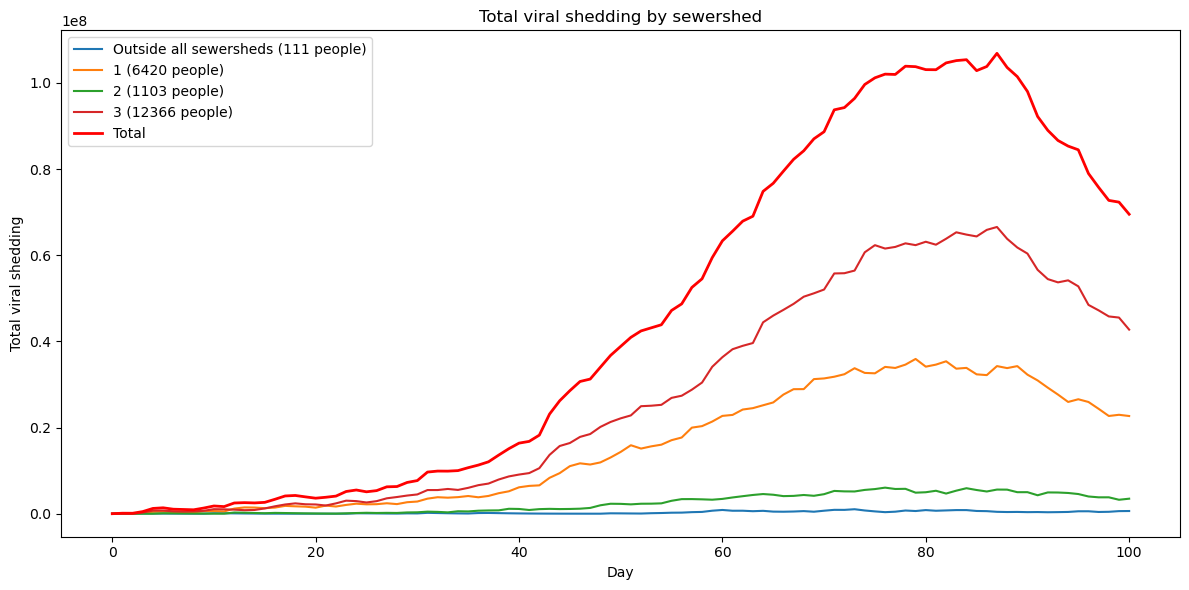

In [34]:
# ==========================================
# 2. Viral shedding values over time by sewershed
# ==========================================
viral_shedding = sim.results['viral_shedding_hist']
sewersheds = np.asarray(sim.people.sewershed)
plt.figure(figsize=(12, 6))
for sid in np.unique(sewersheds):
  mask = sewersheds == sid
  name = sim.sewershed_labels.get(
      sid, 'Outside all sewersheds'
  )  # IDs of sewersheds in the file -> names; 0 and -1 are not in the file
  plt.plot(
      viral_shedding[mask].sum(axis=0),
      label=f'{name} ({mask.sum()} people)',
  )
plt.plot(
    viral_shedding.sum(axis=0),
    linewidth=2,
    color='red',
    label='Total',
)
plt.xlabel('Day')
plt.ylabel('Total viral shedding')
plt.title('Total viral shedding by sewershed')
plt.legend()
plt.tight_layout()
#plt.savefig(f'{plot_dir}/02_shedding_by_sewershed.pdf')
#plt.close()